# EV Perception: Object Detection Evaluation

Precision = TP / (TP + FP). Recall = TP / (TP + FN).
A prediction counts as TP only when its class matches and IoU meets the threshold.
Each ground-truth box can match at most one prediction, processed in confidence order.
This demo reports fixed-threshold Precision/Recall, not mAP.


## Setup and sample download
Run all cells in order. Select your CUDA-enabled Python environment as the notebook kernel.
The install cell uses that kernel. Keep your working PyTorch installation.
Default: 10 labeled images and RF-DETR Medium. Change N for a larger sample.


In [1]:
%pip install rfdetr supervision huggingface_hub pillow matplotlib pyyaml pandas


Note: you may need to restart the kernel to use updated packages.


In [2]:
from huggingface_hub import HfFileSystem
REPO = "dronefreak/BDD100K"
fs = HfFileSystem()
print(fs.ls(f"datasets/{REPO}", detail=False))
print(fs.ls(f"datasets/{REPO}/" + fs.ls(f"datasets/{REPO}", detail=False)[0].split("/")[-1], detail=False)[:10])

c:\Users\andrewli\miniconda3\envs\EV\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


['datasets/dronefreak/BDD100K/data', 'datasets/dronefreak/BDD100K/.gitattributes', 'datasets/dronefreak/BDD100K/README.md', 'datasets/dronefreak/BDD100K/bdd100k_banner.jpg']
['datasets/dronefreak/BDD100K/data/images', 'datasets/dronefreak/BDD100K/data/labels', 'datasets/dronefreak/BDD100K/data/data.yaml']


In [3]:
import os
from huggingface_hub import snapshot_download

SPLIT = "test"   # repository split name; require labels for evaluation
DATA_DIR = os.path.abspath("bdd_det")
N = 10000

all_files = [p.split(f"datasets/{REPO}/")[1] for p in fs.glob(f"datasets/{REPO}/**/*")]
imgs = sorted(p for p in all_files if f"/{SPLIT}/" in f"/{p}" and p.endswith(".jpg"))[:N]
labels = {os.path.splitext(os.path.basename(p))[0]: p
          for p in all_files if f"/{SPLIT}/" in f"/{p}" and p.endswith(".txt")}
lbls = [labels[os.path.splitext(os.path.basename(p))[0]] for p in imgs
        if os.path.splitext(os.path.basename(p))[0] in labels]
if not imgs:
    raise RuntimeError(f"No images found in split {SPLIT!r}.")
if len(lbls) != len(imgs):
    raise RuntimeError("Some images have no label file. Choose a labeled split; missing labels are not empty ground truth.")

yaml = [p for p in all_files if p.endswith((".yaml", ".yml"))]

print(len(imgs), "images |", len(lbls), "label files")
snapshot_download(REPO, repo_type="dataset", local_dir=DATA_DIR,
                  allow_patterns=imgs + lbls + yaml, max_workers=16)

10000 images | 10000 label files


Fetching 20001 files:  66%|██████▌   | 13119/20001 [44:05<04:05, 28.05it/s]  HTTP Error 429 thrown while requesting HEAD https://huggingface.co/datasets/dronefreak/BDD100K/resolve/2e47ffeefc1066a36ea8cefa324aae1dae0b5e33/data/labels/test/shard_000/b9bafa5a-933c3c94.txt
Rate limited. Waiting 171.0s before retry [Retry 1/5].
HTTP Error 429 thrown while requesting HEAD https://huggingface.co/datasets/dronefreak/BDD100K/resolve/2e47ffeefc1066a36ea8cefa324aae1dae0b5e33/data/labels/test/shard_000/b9bafa5a-758fc13c.txt
Rate limited. Waiting 171.0s before retry [Retry 1/5].
Fetching 20001 files:  66%|██████▌   | 13122/20001 [44:05<04:40, 24.54it/s]HTTP Error 429 thrown while requesting HEAD https://huggingface.co/datasets/dronefreak/BDD100K/resolve/2e47ffeefc1066a36ea8cefa324aae1dae0b5e33/data/labels/test/shard_000/b9bafa5a-9d12fc05.txt
Rate limited. Waiting 171.0s before retry [Retry 1/5].
HTTP Error 429 thrown while requesting HEAD https://huggingface.co/datasets/dronefreak/BDD100K/resolve/2

'C:\\Users\\andrewli\\AL_FILE\\UIUC\\EV\\bdd_det'

In [4]:
from pathlib import Path
from PIL import Image

# Use only this run's selected files, not older cached images.
img_paths = [str(Path(DATA_DIR) / p) for p in imgs]
lbl_path = {Path(p).stem: str(Path(DATA_DIR) / p) for p in lbls}

def load(img_path):
    with Image.open(img_path) as source:
        img = source.convert("RGB")
    W, H = img.size
    label_file = lbl_path[Path(img_path).stem]
    boxes = []
    with open(label_file, encoding="utf-8") as f:
        for line in f:
            if not line.strip():
                continue
            c, cx, cy, w, h = map(float, line.split())
            if c != int(c) or w < 0 or h < 0:
                raise ValueError(f"Invalid YOLO label: {line}")
            boxes.append((int(c), [(cx-w/2)*W, (cy-h/2)*H,
                                   (cx+w/2)*W, (cy+h/2)*H]))
    return img, boxes

img, boxes = load(img_paths[0])
print(len(img_paths), "images", boxes[:3])


10000 images [(9, [1000.69888, 281.99232, 1040.6272, 326.91168]), (9, [214.61311999999998, 172.19016, 274.5056, 229.58711999999997]), (9, [797.3152, 313.18596, 829.7568, 341.88444])]


{0: 'person', 1: 'rider', 2: 'car', 3: 'truck', 4: 'bus', 5: 'train', 6: 'motor', 7: 'bike', 8: 'traffic light', 9: 'traffic sign'}


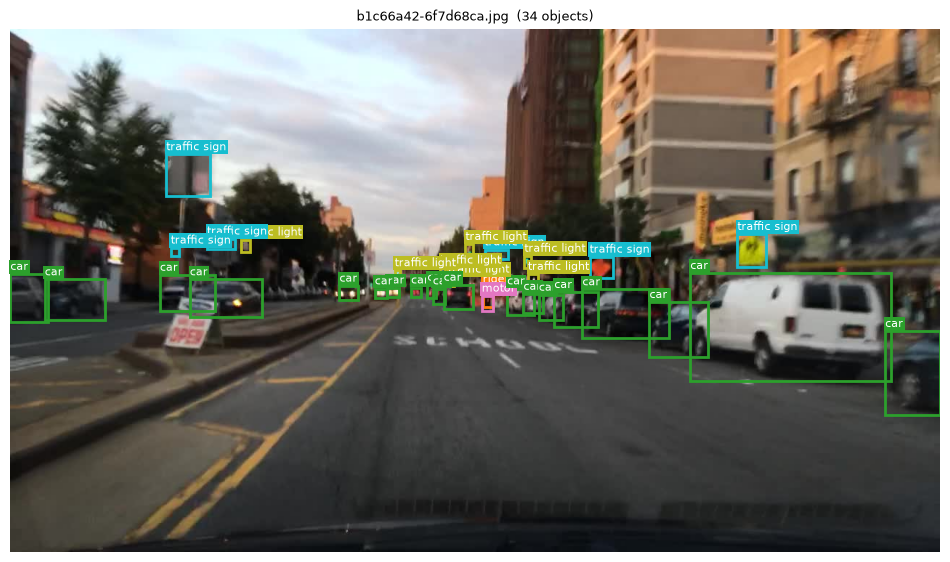

In [5]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import glob, yaml

yaml_files = sorted(
    list(Path(DATA_DIR).rglob("*.yaml"))
    + list(Path(DATA_DIR).rglob("*.yml"))
)
yaml_file = str(yaml_files[0])
cfg = yaml.safe_load(open(yaml_file))

names = cfg["names"]
if isinstance(names, list):
    names = dict(enumerate(names))
names = {int(k): str(v) for k, v in names.items()}
print(names)

colors = plt.cm.tab10.colors

def show(img_path, ax=None):
    img, boxes = load(img_path)
    if ax is None:
        _, ax = plt.subplots(figsize=(12, 7))
    ax.imshow(img)
    for c, (x1, y1, x2, y2) in boxes:
        col = colors[c % len(colors)]
        ax.add_patch(patches.Rectangle((x1, y1), x2 - x1, y2 - y1,
                                       fill=False, edgecolor=col, linewidth=2))
        ax.text(x1, y1 - 2, names[c], color="white", fontsize=8,
                va="bottom", bbox=dict(facecolor=col, edgecolor="none", pad=1))
    ax.set_title(f"{os.path.basename(img_path)}  ({len(boxes)} objects)", fontsize=9)
    ax.axis("off")

show(img_paths[0])

In [6]:
def calculate_IOU(box1, box2):
    x1, y1, x2, y2 = box1
    a1, b1, a2, b2 = box2
    intersection = max(0, min(x2, a2) - max(x1, a1)) * max(0, min(y2, b2) - max(y1, b1))
    area1 = max(0, x2-x1) * max(0, y2-y1)
    area2 = max(0, a2-a1) * max(0, b2-b1)
    union = area1 + area2 - intersection
    return intersection / union if union > 0 else 0.0


def match_boxes(gt, predictions, iou_threshold):
    # predictions: (dataset_class_id, xyxy_box, confidence)
    used = set()
    matches = []
    for cls, box, score in sorted(predictions, key=lambda p: p[2], reverse=True):
        candidates = [(calculate_IOU(box, gt_box), j)
                      for j, (gt_cls, gt_box) in enumerate(gt)
                      if gt_cls == cls and j not in used]
        best_iou, best_j = max(candidates, default=(0.0, -1))
        if best_j >= 0 and best_iou >= iou_threshold:
            used.add(best_j)
            matches.append((cls, best_iou))
    tp = len(matches)
    return tp, len(predictions)-tp, len(gt)-tp, matches


## Load RF-DETR Medium and align classes
Uses the same pretrained RFDETRMedium() model as tst.py.
Images are passed as RGB PIL images. Predictions use supervision.Detections.
COCO and BDD class IDs differ: resolve names before mapping to dataset IDs.
Only shared classes are evaluated; excluded BDD classes are printed.


In [7]:
import torch
import pandas as pd
from rfdetr import RFDETRMedium

# RF-DETR moved this module in newer releases.
try:
    from rfdetr.assets.coco_classes import COCO_CLASSES
except ImportError:
    from rfdetr.util.coco_classes import COCO_CLASSES

CONF_THRESHOLD = 0.25
IOU_THRESHOLDS = [0.50, 0.85]
REQUIRE_ALL_CLASSES = False
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", torch.cuda.get_device_name(0) if DEVICE == "cuda" else "CPU")
model = RFDETRMedium(device=DEVICE)

ALIASES = {"pedestrian": "person", "bike": "bicycle", "motor": "motorcycle"}
def canonical(name):
    name = str(name).strip().lower().replace("_", " ")
    return ALIASES.get(name, name)

dataset_ids = {canonical(name): cls for cls, name in names.items()}
# This notebook uses COCO pretrained weights, matching tst.py.
# For custom-trained weights, supply the complete supported class names instead.
model_class_names = (list(COCO_CLASSES.values()) if isinstance(COCO_CLASSES, dict)
                     else list(COCO_CLASSES))
evaluated_classes = {dataset_ids[canonical(name)] for name in model_class_names
                     if canonical(name) in dataset_ids}
excluded = [names[cls] for cls in names if cls not in evaluated_classes]
print("Evaluated classes:", [names[cls] for cls in sorted(evaluated_classes)])
print("Excluded dataset classes:", excluded)
if not evaluated_classes:
    raise ValueError("No shared classes; check dataset names and ALIASES.")
if REQUIRE_ALL_CLASSES and excluded:
    raise ValueError("Pretrained model does not support all dataset classes.")

def detections_to_predictions(detections):
    # Newer RF-DETR resolves sparse COCO IDs internally into class_name.
    resolved_names = detections.data.get("class_name")
    if detections.class_id is None or detections.confidence is None:
        raise ValueError("RF-DETR returned detections without classes/confidence.")
    predictions = []
    for i, (box, cls, conf) in enumerate(zip(detections.xyxy,
                                            detections.class_id,
                                            detections.confidence)):
        if resolved_names is not None:
            class_name = str(resolved_names[i])
        else:
            # Compatibility with older RF-DETR's pretrained COCO ID table.
            class_name = COCO_CLASSES[int(cls)]
        if not class_name:
            raise ValueError(f"Unresolved model class ID: {cls}")
        dataset_cls = dataset_ids.get(canonical(class_name))
        if dataset_cls is not None:
            predictions.append((dataset_cls, [float(x) for x in box], float(conf)))
    return predictions

def predict_boxes(img_path):
    with Image.open(img_path) as source:
        img_rgb = source.convert("RGB")
    detections = model.predict(img_rgb, threshold=CONF_THRESHOLD)
    return detections_to_predictions(detections)


Device: NVIDIA GeForce RTX 5060 Laptop GPU
[2026-10-10 00:47:36] [INFO] rf-detr - File C:\Users\andrewli\.roboflow\models\rf-detr-medium.pth already exists with correct MD5 hash.


[2026-10-10 00:47:36] [WARNING] rf-detr - Using a different number of positional encodings than DINOv2, which means we're not loading DINOv2 backbone weights. This is not a problem if finetuning a pretrained RF-DETR model.
[2026-10-10 00:47:36] [WARNING] rf-detr - Using patch size 16 instead of 14, which means we're not loading DINOv2 backbone weights. This is not a problem if finetuning a pretrained RF-DETR model.


[2026-10-10 00:47:37] [INFO] rf-detr - File C:\Users\andrewli\.roboflow\models\rf-detr-medium.pth already exists with correct MD5 hash.
Evaluated classes: ['person', 'car', 'truck', 'bus', 'train', 'motor', 'bike', 'traffic light']
Excluded dataset classes: ['rider', 'traffic sign']


## Evaluate
Inference runs once per image. The same predictions are evaluated at both IoU thresholds.
Mean matched IoU includes TP matches only; it is undefined when there are no matches.
For another detector, provide predict_fn(path) returning (dataset_class_id, xyxy, confidence)
and pass the class IDs it supports through class_ids.


In [8]:
def evaluate_model(predict_fn, paths, class_ids, thresholds=(0.5, 0.85)):
    records = []
    details = []
    for i, path in enumerate(paths):
        _, gt_all = load(path)
        unknown = {cls for cls, box in gt_all} - set(names)
        if unknown:
            raise ValueError(f"Label class IDs missing from YAML: {unknown}")
        gt = [(cls, box) for cls, box in gt_all if cls in class_ids]
        pred = [(cls, box, conf) for cls, box, conf in predict_fn(path) if cls in class_ids]
        details.append(dict(path=path, gt=gt, predictions=pred))
        for threshold in thresholds:
            tp, fp, fn, matches = match_boxes(gt, pred, threshold)
            records.append(dict(image=Path(path).name, iou_threshold=threshold,
                                TP=tp, FP=fp, FN=fn,
                                matched_iou_sum=sum(iou for _, iou in matches)))
        print(f"{i+1}/{len(paths)}: {Path(path).name}")
    if not records:
        raise ValueError("No images to evaluate.")
    per_image = pd.DataFrame(records)
    totals = per_image.groupby("iou_threshold")[["TP", "FP", "FN", "matched_iou_sum"]].sum()
    totals["Precision"] = totals.TP / (totals.TP + totals.FP).replace(0, float("nan"))
    totals["Recall"] = totals.TP / (totals.TP + totals.FN).replace(0, float("nan"))
    totals["Mean matched IoU"] = totals.matched_iou_sum / totals.TP.replace(0, float("nan"))
    return totals.drop(columns="matched_iou_sum"), per_image, details

summary, per_image, details = evaluate_model(predict_boxes, img_paths,
                                            evaluated_classes, IOU_THRESHOLDS)
display(summary.round(4))
display(per_image.drop(columns="matched_iou_sum"))


[2026-10-10 00:47:41] [WARNING] rf-detr - Model is not optimized for inference. Latency may be higher than expected. For full GPU throughput (e.g. ~8x on T4 via FP16 Tensor Cores), call model.inference(dtype=torch.float16).


1/10000: b1c66a42-6f7d68ca.jpg
2/10000: b1c81faa-3df17267.jpg
3/10000: b1c81faa-c80764c5.jpg
4/10000: b1c9c847-3bda4659.jpg
5/10000: b1ca2e5d-84cf9134.jpg
6/10000: b1ca8418-84a133a0.jpg
7/10000: b1cac6a7-04e33135.jpg
8/10000: b1cd1e94-26dd524f.jpg
9/10000: b1cd1e94-549d0bfe.jpg
10/10000: b1ceb32e-3f481b43.jpg
11/10000: b1ceb32e-51852abe.jpg
12/10000: b1ceb32e-813f84b2.jpg
13/10000: b1ceb32e-a106591d.jpg
14/10000: b1cebfb7-284f5117.jpg
15/10000: b1d0091f-75824d0d.jpg
16/10000: b1d0091f-f2c2d2ae.jpg
17/10000: b1d0a191-03dcecc2.jpg
18/10000: b1d0a191-06deb55d.jpg
19/10000: b1d0a191-28f0e779.jpg
20/10000: b1d0a191-2ed2269e.jpg
21/10000: b1d0a191-5490450b.jpg
22/10000: b1d0a191-65deaeef.jpg
23/10000: b1d0a191-de8948f6.jpg
24/10000: b1d10d08-5b108225.jpg
25/10000: b1d10d08-743fd86c.jpg
26/10000: b1d10d08-c35503b8.jpg
27/10000: b1d10d08-da110fcb.jpg
28/10000: b1d10d08-ec660956.jpg
29/10000: b1d22449-117aa773.jpg
30/10000: b1d22449-15fb948f.jpg
31/10000: b1d22ed6-f1cac061.jpg
32/10000: b1d3907

,TP,FP,FN,Precision,Recall,Mean matched IoU
iou_threshold,,,,,,
0.50,89582,63857,60387,0.5838,0.5973,0.7725
0.85,31950,121489,118019,0.2082,0.2130,0.9159


,image,iou_threshold,TP,FP,FN
0,b1c66a42-6f7d68ca.jpg,0.50,17,10,10
1,b1c66a42-6f7d68ca.jpg,0.85,9,18,18
2,b1c81faa-3df17267.jpg,0.50,1,1,2
3,b1c81faa-3df17267.jpg,0.85,0,2,3
4,b1c81faa-c80764c5.jpg,0.50,2,1,9
...,...,...,...,...,...
19995,fe1f2409-5b415eb7.jpg,0.85,0,5,2
19996,fe1f2409-c16ea1ed.jpg,0.50,18,3,10
19997,fe1f2409-c16ea1ed.jpg,0.85,5,16,23
19998,fe1f55fa-19ba3600.jpg,0.50,3,5,5


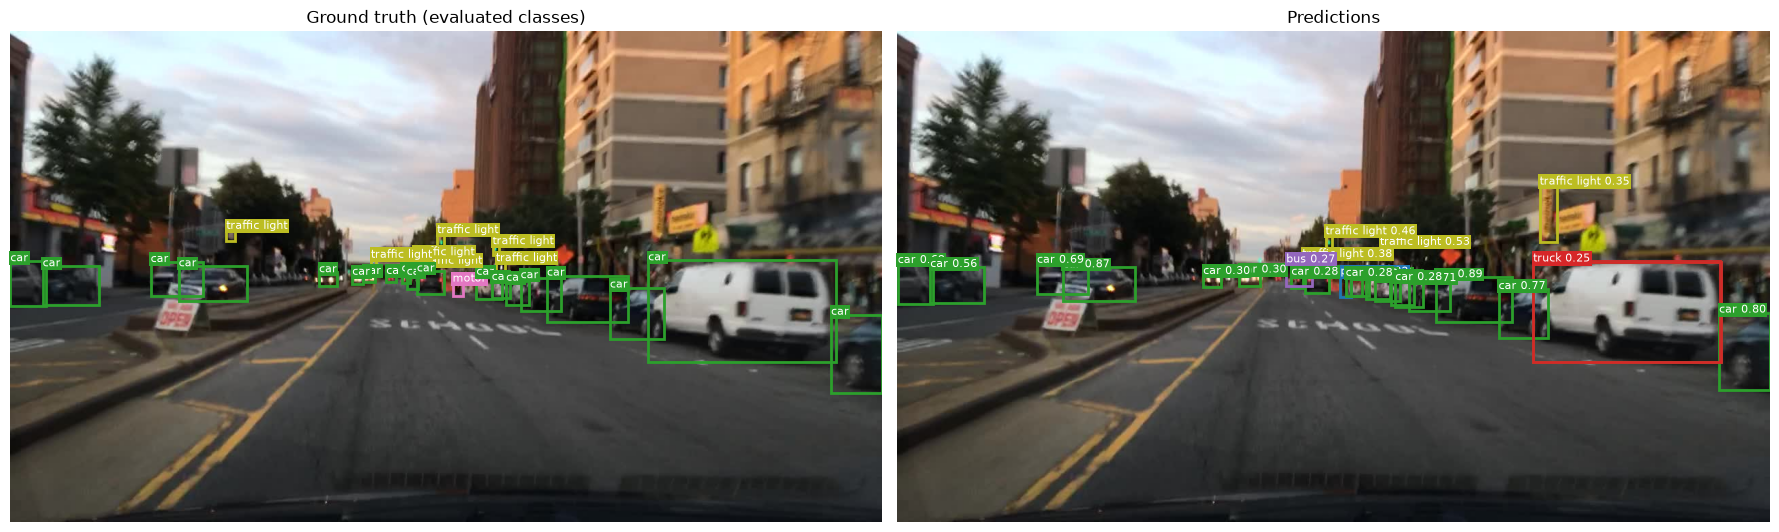

In [9]:
def show_comparison(item):
    img, _ = load(item["path"])
    fig, axes = plt.subplots(1, 2, figsize=(18, 6))
    for ax, title, entries in zip(axes, ["Ground truth (evaluated classes)", "Predictions"],
                                  [item["gt"], item["predictions"]]):
        ax.imshow(img)
        for entry in entries:
            cls, (x1, y1, x2, y2) = entry[:2]
            col = colors[cls % len(colors)]
            ax.add_patch(patches.Rectangle((x1, y1), x2-x1, y2-y1,
                                           fill=False, edgecolor=col, linewidth=2))
            label = names[cls] + (f" {entry[2]:.2f}" if len(entry) == 3 else "")
            ax.text(x1, y1, label, color="white", fontsize=8,
                    bbox=dict(facecolor=col, edgecolor="none", pad=1))
        ax.set_title(title)
        ax.axis("off")
    plt.tight_layout()
    plt.show()

show_comparison(details[0])


In [10]:
rows = []

for threshold in IOU_THRESHOLDS:
    for cls in sorted(evaluated_classes):
        tp = fp = fn = 0
        matched_ious = []

        for item in details:
            gt = [box for box in item["gt"] if box[0] == cls]
            pred = [box for box in item["predictions"] if box[0] == cls]

            t, f, n, matches = match_boxes(gt, pred, threshold)
            tp += t
            fp += f
            fn += n
            matched_ious.extend(iou for _, iou in matches)

        rows.append({
            "IoU threshold": threshold,
            "Class": names[cls],
            "TP": tp,
            "FP": fp,
            "FN": fn,
            "Precision": tp / (tp + fp) if tp + fp else float("nan"),
            "Recall": tp / (tp + fn) if tp + fn else float("nan"),
            "Mean matched IoU": (
                sum(matched_ious) / len(matched_ious)
                if matched_ious else float("nan")
            ),
        })

per_class = pd.DataFrame(rows)
display(per_class.round(4))

,IoU threshold,Class,TP,FP,FN,Precision,Recall,Mean matched IoU
0,0.50,person,7717,7040,5545,0.5229,0.5819,0.7405
1,0.50,car,65586,29973,36920,0.6863,0.6398,0.7885
2,0.50,truck,2817,10661,1428,0.2090,0.6636,0.8525
3,0.50,bus,851,775,746,0.5234,0.5329,0.8775
4,0.50,train,4,51,11,0.0727,0.2667,0.8723
5,0.50,motor,221,259,231,0.4604,0.4889,0.7511
6,0.50,bike,438,392,569,0.5277,0.4350,0.7287
7,0.50,traffic light,11948,14706,14937,0.4483,0.4444,0.6808
8,0.85,person,1608,13149,11654,0.1090,0.1212,0.8973
9,0.85,car,26802,68757,75704,0.2805,0.2615,0.9174
